In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ratings = pd.read_csv("data/ratings.csv")
movies = pd.read_csv("data/movies.csv")

display(ratings.head())
display(movies.head())

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


userId: the person who gave the rating

movieId: the movie that recieved this rating

rating: actual rating from 0 to 5

timestamp: when this rating was given (probably will not be used)

required: number of unique users, unique movies, ratings, sparsity

In [ ]:
unique_users = ratings['userId'].nunique()
unique_movies = ratings['movieId'].nunique()
rating_num = len(ratings)

total = unique_users * unique_movies
sparsity = 1 - (rating_num / total)

print(f'Number of unique users: {unique_users}')
print(f'Number of unique movies: {unique_movies}')
print(f'Number of ratings: {rating_num}')
print(f'Sparsity of the dataset: {sparsity:.4f}')

Number of unique users: 610
Number of unique movies: 9724
Number of ratings: 100836
Sparsity of the dataset: 0.9830


build the item-user matrix

rows = userId, columns = movieId, values = rating, missing = NaN

In [ ]:
matrix = ratings.pivot_table(
    index="userId",
    columns="movieId",
    values="rating"
)

print("Matrix shape:", matrix.shape)
display(matrix.head())

Matrix shape: (610, 9724)


movieId,1,2,3,4,5,6,7,8,9,10,...,193565,193567,193571,193573,193579,193581,193583,193585,193587,193609
userId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,4.0,NaN,NaN,4.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


plotting the distribution of ratings:

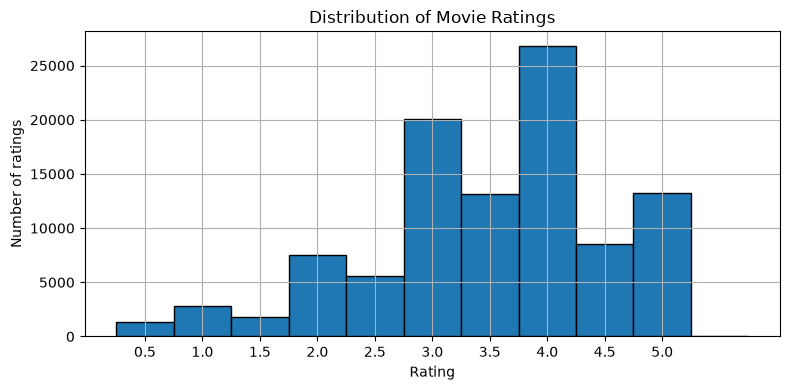

In [ ]:
# Distribution of individual ratings
plt.figure(figsize=(8, 4))

ratings["rating"].hist(
    bins=np.arange(0.25, 5.76, 0.5),
    edgecolor="black"
)

plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.title("Distribution of Movie Ratings")
plt.xticks(np.arange(0.5, 5.1, 0.5))
plt.tight_layout()
plt.show()

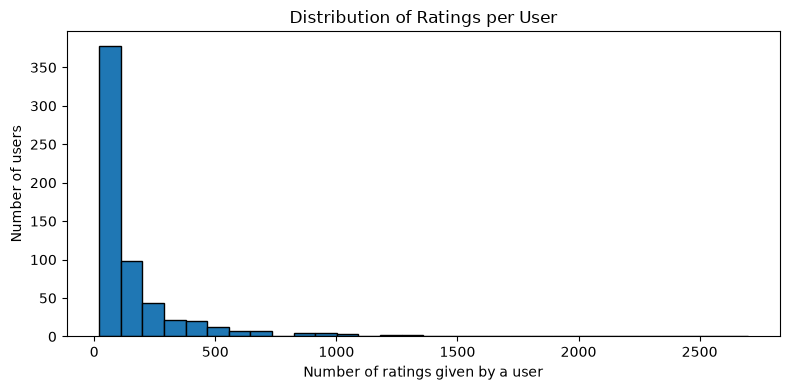

In [ ]:
ratings_per_user = ratings.groupby("userId").size()

plt.figure(figsize=(8, 4))

plt.hist(ratings_per_user, bins=30, edgecolor="black")

plt.xlabel("Number of ratings given by a user")
plt.ylabel("Number of users")
plt.title("Distribution of Ratings per User")
plt.tight_layout()
plt.show()

In [ ]:
def get_co_rated(matrix, a, b, axis="index"):
    if axis == "index":
        vec_a = matrix.loc[a] #.loc[a] selects a row
        vec_b = matrix.loc[b]

    elif axis == "columns":
        vec_a = matrix[a]
        vec_b = matrix[b]

    # keep only positions where both entries are present
    mask = vec_a.notna() & vec_b.notna()  #notna return true if the value isn't missing 

    return (
        vec_a[mask].to_numpy(dtype=float),
        vec_b[mask].to_numpy(dtype=float)
    )

In [ ]:
# test the function
user_a, user_b = get_co_rated(matrix, 1, 2, axis="index")

print("User 1 shared ratings:", user_a)
print("User 2 shared ratings:", user_b)
print(f"Length of shared ratings: {len(user_a)}")

User 1 shared ratings: [5. 5.]
User 2 shared ratings: [4. 4.]
Length of shared ratings: 2


In [ ]:
def euclidean_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    # Check for valid lengths and finite numbers
    if len(vec1) != len(vec2) or len(vec1) < 2:
        return np.nan
    
    if not (np.isfinite(vec1).all() and np.isfinite(vec2).all()):
        return np.nan

    # Calculate Euclidean distance and convert to similarity
    distance = np.sqrt(np.sum((vec1 - vec2) ** 2))
    return 1 / (1 + distance)

In [ ]:
def cosine_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    # Check for valid lengths and finite numbers
    if len(vec1) != len(vec2) or len(vec1) < 2:
        return np.nan
    
    if not (np.isfinite(vec1).all() and np.isfinite(vec2).all()):
        return np.nan

    # Calculate Cosine similarity
    dot_product = np.dot(vec1, vec2)

    norm_1 = np.linalg.norm(vec1)
    norm_2 = np.linalg.norm(vec2)

    if norm_1 == 0 or norm_2 == 0:
        return np.nan


    return dot_product / (norm_1 * norm_2)



In [ ]:

def pearson_similarity(vec1, vec2):
    vec1 = np.asarray(vec1, dtype=float)
    vec2 = np.asarray(vec2, dtype=float)

    if len(vec1) != len(vec2) or len(vec1) < 2:
        return np.nan

    if not np.isfinite(vec1).all() or not np.isfinite(vec2).all():
        return np.nan

    centered_1 = vec1 - np.mean(vec1)
    centered_2 = vec2 - np.mean(vec2)

    # Use the centered vectors, not the original vectors
    norm_1 = np.linalg.norm(centered_1)
    norm_2 = np.linalg.norm(centered_2)

    if norm_1 == 0 or norm_2 == 0:
        return np.nan

    return np.dot(centered_1, centered_2) / (norm_1 * norm_2)


In [ ]:
# checking the functions

A = np.array([5, 4, 5, 3])
B = np.array([3, 2, 3, 1])

print(euclidean_similarity(A, B))
print(cosine_similarity(A, B))
print(pearson_similarity(A, B))

0.2
0.06621221919717306
1.0


In [769]:
def find_k_nearest_users(matrix, target_user, k, similarity_fn):
    users=matrix.index.tolist()
    k_nearest_users = {}
    for user in users:
        if user != target_user:
            user_a,user_b=get_co_rated(matrix, target_user, user, axis="index")
            if(len(user_a)>=2):
                similarity= float(similarity_fn(user_a, user_b))
                smilarities[user] = similarity

    k_nearest_users = sorted(similarities.items(), key=lambda x: x[1], reverse=True)
    return k_nearest_users[:k]

In [770]:
def predict_rating_user_based(matrix, target_user, target_item, k, similarity_fn) :
    k_nearest_users = find_k_nearest_users(matrix, target_user, k, similarity_fn)
    numerator = 0
    denominator = 0
    for user in k_nearest_users:
        user_id=user[0]
        rating = matrix.loc[user_id, target_item]
        if pd.notna(rating):
            similarity = user[1]
            numerator += similarity * rating
            denominator += abs(similarity)
    if denominator == 0:
        return np.nan
    return numerator/denominator



In [771]:
def find_k_nearest_items(matrix, target_item, k, similarity_fn):
    movies=matrix.columns.tolist()
    k_nearest_movies={}
    for movie in movies:
        if movie!=target_item:
            item_a,item_b=get_co_rated(matrix, target_item, movie, axis="columns")
            if(len(item_a)>=2):
                similarity= float(similarity_fn(item_a, item_b))
                if np.isnan(similarity) or similarity <= 0:   # drop NaN and negative
                    continue
                k_nearest_movies[movie] = similarity
    k_nearest_movies = sorted(k_nearest_movies.items(), key=lambda x: x[1], reverse=True)
    return k_nearest_movies[:k]

In [772]:
def predict_rating_item_based(matrix, target_user, target_item, k, similarity_fn):
    k_nearest_items= find_k_nearest_items(matrix, target_item, k, similarity_fn)
    numerator=0
    denominator=0
    for item in k_nearest_items:
        item_id=item[0]
        rating=matrix.loc[target_user,item_id]
        if pd.notna(rating):
            similarity = item[1]
            numerator += similarity * rating
            denominator += abs(similarity)
    if denominator == 0:
        return np.nan
    return numerator/denominator



I reused both methods from part C, but instead of searching the rows(users), I searched the columns (movies) to get the nearest movies to the target movie, also the prediction was made on the nearest movies that the user rated.

In [773]:
def mean_centering(matrix,target_user,target_item,k,similarity_fn):
    user_means=matrix.mean(axis=1) #get the mean of all the rows
    centered_matrix = matrix.sub(user_means,axis=0) #subtract the mean from each row.
    rating=predict_rating_user_based(centered_matrix,target_user,target_item,k,similarity_fn)
    mean_user_rating=np.nanmean(np.asarray(matrix.loc[target_user]))
    return np.clip(rating + mean_user_rating, 0.5, 5)
        
        

In [774]:
def calculate_RMSE(actual,predicted):
    actual_vec=np.asarray(actual)
    predicted_vec=np.asarray(predicted)
    return np.sqrt(np.nanmean((actual - predicted) ** 2))

In [775]:
def get_predicted_matrix(matrix,prediction_fn,k,similarity_fn):
    users=matrix.index.tolist()
    movies=matrix.columns.tolist()
    predicted_ratings=pd.DataFrame(np.nan,index=matrix.index,columns=matrix.columns)
    matrix_copy=matrix.copy()
    
    for user in users:
        for movie in movies:
            true_rating=matrix.loc[user,movie]
            if pd.isna(matrix.loc[user, movie]):
                continue
            matrix_copy.loc[user,movie]=np.nan
            prediction=prediction_fn(matrix_copy,user,movie,k,similarity_fn)
            matrix_copy.loc[user,movie]=true_rating
            predicted_ratings.loc[user,movie]=prediction
            
    return predicted_ratings
